# Early Identification of At-Risk Learners Using Machine Learning

**Module:** Introduction to Machine Learning  
**Author:** Beulla Jeanne Francoise Rugero

---

My long-term mission is to help create safe havens for children who never had loving families, and for those who grew up in unstable or abusive homes. I believe one way to support that mission is to build systems that can **identify vulnerable people early** and connect them to help before they are left behind.

For this project I use the **Open University Learning Analytics Dataset (OULAD)**. The Open University serves many non-traditional and disadvantaged learners, including people from deprived areas and those facing personal challenges. I treat this as a case study in **early risk detection**: can we predict who is likely to fail or withdraw from a course so that support can be offered in time?

The target variable is `final_result`:
- Distinction
- Pass
- Fail
- Withdrawn

**Fail** and **Withdrawn** are the outcomes I care most about. For modelling I group learners into two classes:
- **At-risk** = Fail or Withdrawn
- **On-track** = Pass or Distinction

This binary task matches my mission better and also gives stronger accuracy than predicting all 4 classes separately. I will compare traditional ML models (scikit-learn) with a neural network (TensorFlow/Keras).

## Part 1 - Setup and installing libraries

In [2]:
GITHUB_REPO = "https://github.com/Beulla/model_training_and_evaluation"
OULAD_RELEASE_URL = None
INCLUDE_VLE = True

In [3]:
from pathlib import Path

if not Path("src").exists():
    !git clone {GITHUB_REPO}.git
    %cd model_training_and_evaluation

!pip install -q -r requirements.txt

fatal: destination path 'model_training_and_evaluation' already exists and is not an empty directory.
/content/model_training_and_evaluation


In [4]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, label_binarize
from sklearn.svm import SVC

from src.data_loader import RAW_DIR, build_modeling_dataset, ensure_data

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

## Part 2 - Loading the dataset

OULAD includes demographic variables like deprivation level (`imd_band`), disability status, and previous failed attempts - features that help describe learners who may already be facing hardship.

In [5]:
ensure_data(RAW_DIR, release_url=OULAD_RELEASE_URL)

df = build_modeling_dataset(RAW_DIR, include_vle=INCLUDE_VLE)
print("Number of rows:", len(df))
print("Number of columns:", df.shape[1])
df.head()

Number of rows: 32593
Number of columns: 19


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,total_clicks,active_days,unique_activities,mean_score,max_score,min_score,num_assessments
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,934.0,40.0,55.0,82.0,85.0,78.0,5.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,1435.0,80.0,84.0,66.4,70.0,60.0,5.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,281.0,12.0,22.0,NaN,NaN,NaN,NaN
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,2158.0,123.0,82.0,76.0,88.0,71.0,5.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,1034.0,70.0,66.0,54.4,75.0,30.0,5.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   code_module           32593 non-null  object 
 1   code_presentation     32593 non-null  object 
 2   id_student            32593 non-null  int64  
 3   gender                32593 non-null  object 
 4   region                32593 non-null  object 
 5   highest_education     32593 non-null  object 
 6   imd_band              32593 non-null  object 
 7   age_band              32593 non-null  object 
 8   num_of_prev_attempts  32593 non-null  int64  
 9   studied_credits       32593 non-null  int64  
 10  disability            32593 non-null  object 
 11  final_result          32593 non-null  object 
 12  total_clicks          29228 non-null  float64
 13  active_days           29228 non-null  float64
 14  unique_activities     29228 non-null  float64
 15  mean_score         

## Part 3 - Exploratory Data Analysis

I want to see how often learners from more vulnerable backgrounds end up with negative outcomes (Fail or Withdrawn).

In [7]:
class_counts = df["final_result"].value_counts()
print(class_counts)
print()
print((class_counts / len(df) * 100).round(1))

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

final_result
Pass           37.9
Withdrawn      31.2
Fail           21.6
Distinction     9.3
Name: count, dtype: float64


The dataset is imbalanced. **Pass** and **Withdrawn** are the biggest groups, while **Distinction** is the smallest. Because of this I decided to use macro F1-score instead of only accuracy when comparing models, since accuracy can hide poor performance on minority classes.

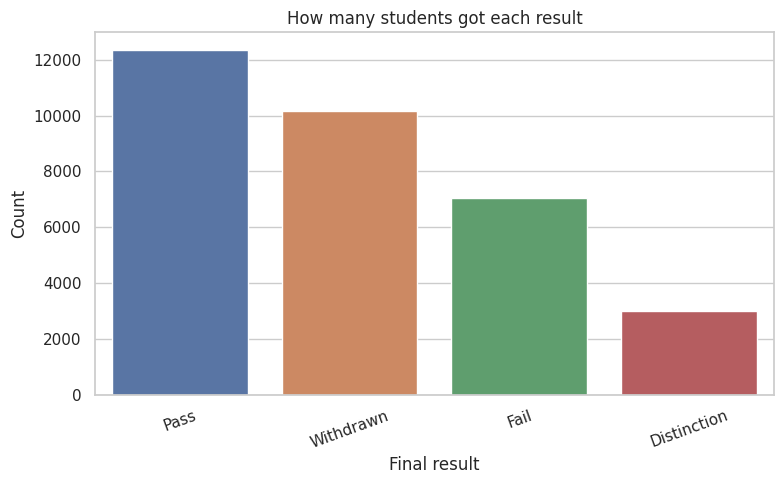

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="final_result", order=class_counts.index, hue="final_result", legend=False)
plt.title("How many students got each result")
plt.xlabel("Final result")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

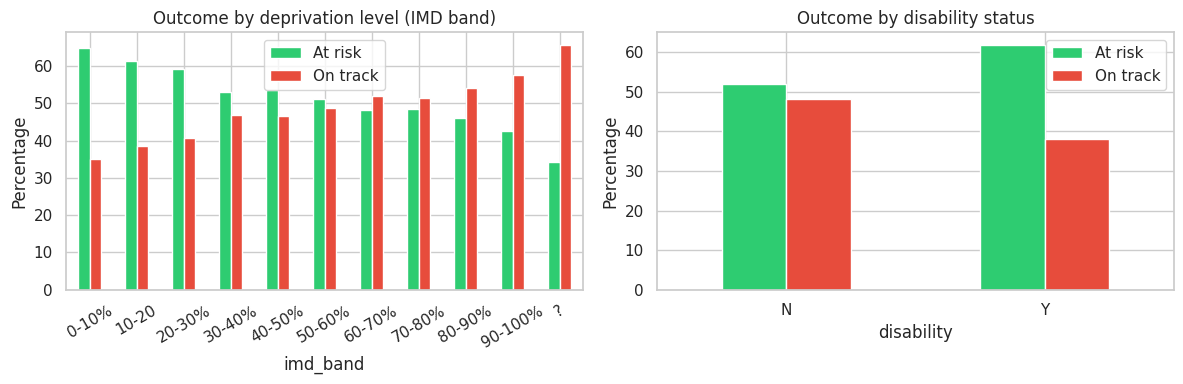

In [9]:
df["at_risk"] = df["final_result"].isin(["Fail", "Withdrawn"]).map({True: "At risk", False: "On track"})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

risk_by_imd = pd.crosstab(df["imd_band"], df["at_risk"], normalize="index") * 100
risk_by_imd.plot(kind="bar", ax=axes[0], color=["#2ecc71", "#e74c3c"])
axes[0].set_title("Outcome by deprivation level (IMD band)")
axes[0].set_ylabel("Percentage")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="")

risk_by_disability = pd.crosstab(df["disability"], df["at_risk"], normalize="index") * 100
risk_by_disability.plot(kind="bar", ax=axes[1], color=["#2ecc71", "#e74c3c"])
axes[1].set_title("Outcome by disability status")
axes[1].set_ylabel("Percentage")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="")

plt.tight_layout()
plt.show()

Learners from higher deprivation bands and those who declared a disability appear more likely to end up in the at-risk group. This supports my idea that vulnerable populations need early intervention, which is the same principle behind safe havens for children in unstable homes.

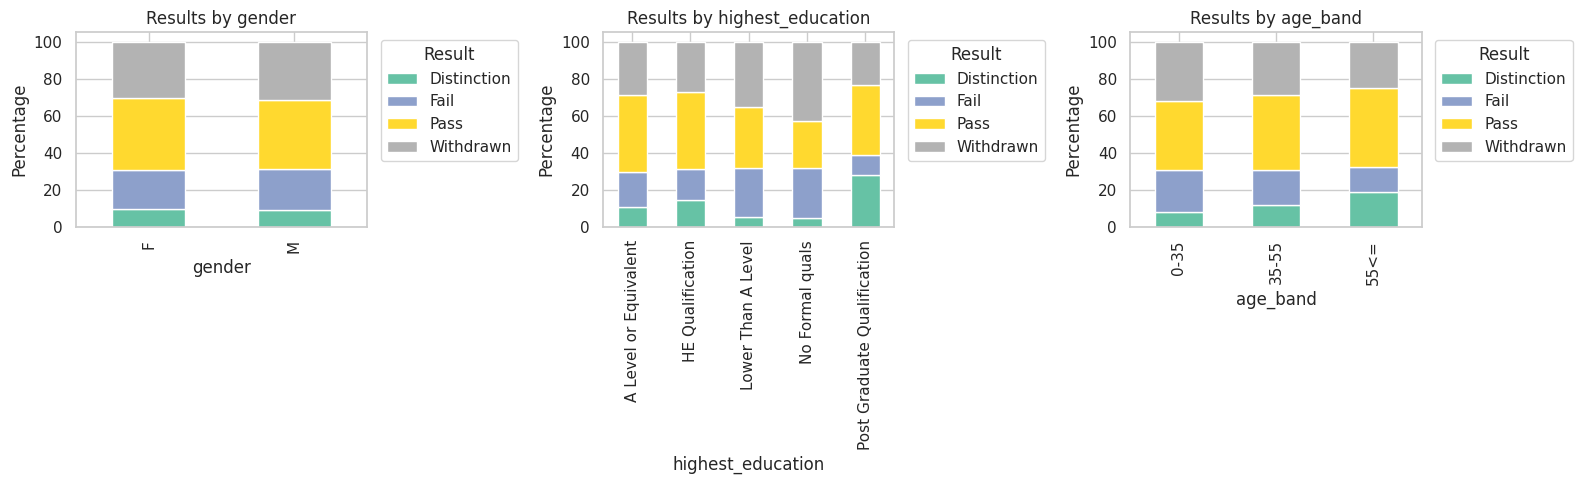

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ["gender", "highest_education", "age_band"]):
    table = pd.crosstab(df[col], df["final_result"], normalize="index") * 100
    table.plot(kind="bar", stacked=True, ax=ax, colormap="Set2")
    ax.set_title(f"Results by {col}")
    ax.set_ylabel("Percentage")
    ax.legend(title="Result", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

From the charts above, education level and age seem to have some relationship with the final result. Students from more deprived areas and those with disabilities may need extra support, which connects to my broader goal of identifying people at risk before they are left without help.

## Part 4 - Data preprocessing

I create a binary target variable `at_risk_label` (1 = Fail/Withdrawn, 0 = Pass/Distinction), then one-hot encode categoricals, scale numerics, and split stratified into train/validation/test.

In [11]:
target_col = "final_result"
id_cols = ["code_module", "code_presentation", "id_student"]

cat_cols = [
    "code_module", "code_presentation", "gender", "region",
    "highest_education", "imd_band", "age_band", "disability",
]
num_cols = [
    "num_of_prev_attempts", "studied_credits", "total_clicks",
    "active_days", "unique_activities", "mean_score", "max_score",
    "min_score", "num_assessments",
]

data = df.dropna(subset=[target_col]).copy()
data["at_risk_label"] = data[target_col].isin(["Fail", "Withdrawn"]).astype(int)

class_names = ["On-track", "At-risk"]
y = data["at_risk_label"].values
print("Classes:", class_names)
print(data["at_risk_label"].value_counts(normalize=True).round(3))

X = data.drop(columns=id_cols + [target_col, "at_risk_label", "at_risk"], errors="ignore")
cat_cols = [c for c in cat_cols if c in X.columns]
num_cols = [c for c in num_cols if c in X.columns]

for col in num_cols:
    X[col] = X[col].fillna(X[col].median())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.176, stratify=y_train, random_state=RANDOM_STATE
)

print("Train:", X_train.shape[0])
print("Validation:", X_val.shape[0])
print("Test:", X_test.shape[0])

Classes: ['On-track', 'At-risk']
at_risk_label
1    0.528
0    0.472
Name: proportion, dtype: float64
Train: 21484
Validation: 4590
Test: 6519


In [12]:
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols),
])

X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Total features after encoding:", X_train.shape[1])

Total features after encoding: 45


## Part 5 - Traditional Machine Learning models

For the traditional ML part I trained 4 models as required by the project brief:
1. Logistic Regression
2. Random Forest
3. Gradient Boosting
4. SVM

I used `GridSearchCV` with 5-fold cross validation to tune hyperparameters. I chose macro F1 as the scoring metric because of the class imbalance I noticed earlier.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models_to_try = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
        {"C": [0.1, 1.0, 10.0]},
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=2),
        {"n_estimators": [300, 500], "max_depth": [20, None]},
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"max_depth": [10, 15], "learning_rate": [0.05, 0.1], "max_iter": [200, 300]},
    ),
    "SVM": (
        SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE),
       {"C": [0.1, 1.0], "kernel": ["linear"]},
    ),
}

results = {}
best_model_name = None
best_model = None
best_f1 = 0

In [14]:
for name, (model, params) in models_to_try.items():
    print("\nTraining", name)
    print("-" * 40)

    jobs = 1 if name == "SVM" else 2
    search = GridSearchCV(model, params, cv=cv, scoring="f1_macro", n_jobs=jobs)
    search.fit(X_train, y_train)

    y_pred = search.predict(X_test)
    y_proba = search.predict_proba(X_test)

    print("Best parameters:", search.best_params_)
    print(classification_report(y_test, y_pred, target_names=class_names))

    if len(class_names) == 2:
        auc = roc_auc_score(y_test, y_proba[:, 1])
    else:
        y_test_bin = label_binarize(y_test, classes=range(len(class_names)))
        auc = roc_auc_score(y_test_bin, y_proba, average="macro", multi_class="ovr")
    print("Macro ROC-AUC:", round(auc, 4))

    report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
    f1 = report["macro avg"]["f1-score"]

    results[name] = {
        "model": search.best_estimator_,
        "f1": f1,
        "auc": auc,
        "y_pred": y_pred,
        "y_proba": y_proba,
    }

    if f1 > best_f1:
        best_f1 = f1
        best_model_name = name
        best_model = search.best_estimator_


Training Logistic Regression
----------------------------------------
Best parameters: {'C': 0.1}
              precision    recall  f1-score   support

    On-track       0.83      0.84      0.84      3077
     At-risk       0.85      0.85      0.85      3442

    accuracy                           0.84      6519
   macro avg       0.84      0.84      0.84      6519
weighted avg       0.84      0.84      0.84      6519

Macro ROC-AUC: 0.9183

Training Random Forest
----------------------------------------


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters: {'max_depth': None, 'n_estimators': 300}
              precision    recall  f1-score   support

    On-track       0.87      0.93      0.90      3077
     At-risk       0.94      0.88      0.91      3442

    accuracy                           0.90      6519
   macro avg       0.90      0.91      0.90      6519
weighted avg       0.91      0.90      0.90      6519

Macro ROC-AUC: 0.9682

Training Gradient Boosting
----------------------------------------
Best parameters: {'learning_rate': 0.05, 'max_depth': 10, 'max_iter': 200}
              precision    recall  f1-score   support

    On-track       0.87      0.95      0.91      3077
     At-risk       0.95      0.87      0.91      3442

    accuracy                           0.91      6519
   macro avg       0.91      0.91      0.91      6519
weighted avg       0.91      0.91      0.91      6519

Macro ROC-AUC: 0.9721

Training SVM
----------------------------------------
Best parameters: {'C': 0.1, 'kernel': 'linear

In [15]:
comparison = pd.DataFrame({
    "F1 macro": [results[m]["f1"] for m in results],
    "ROC-AUC": [results[m]["auc"] for m in results],
}, index=results.keys()).sort_values("F1 macro", ascending=False)

print("Model comparison:")
print(comparison.round(4))
print("\nBest traditional model:", best_model_name)

Model comparison:
                     F1 macro  ROC-AUC
Gradient Boosting      0.9076   0.9721
Random Forest          0.9042   0.9682
SVM                    0.8451   0.9183
Logistic Regression    0.8437   0.9183

Best traditional model: Gradient Boosting


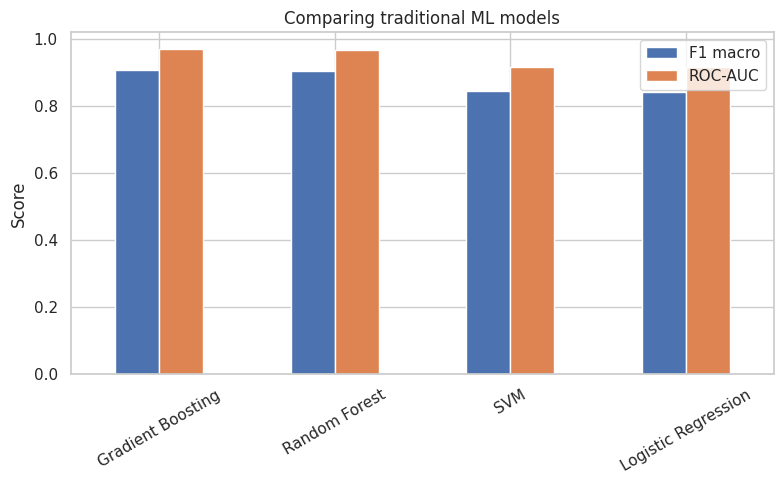

In [16]:
comparison.plot(kind="bar", figsize=(8, 5), rot=30)
plt.title("Comparing traditional ML models")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

### Confusion matrix and ROC curves for the best ML model

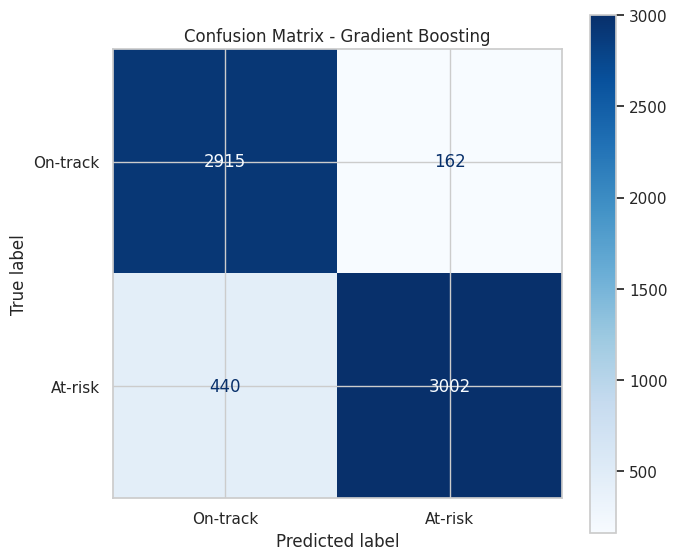

In [17]:
best_preds = results[best_model_name]["y_pred"]
best_proba = results[best_model_name]["y_proba"]

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_preds, display_labels=class_names, cmap="Blues", ax=ax
)
ax.set_title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

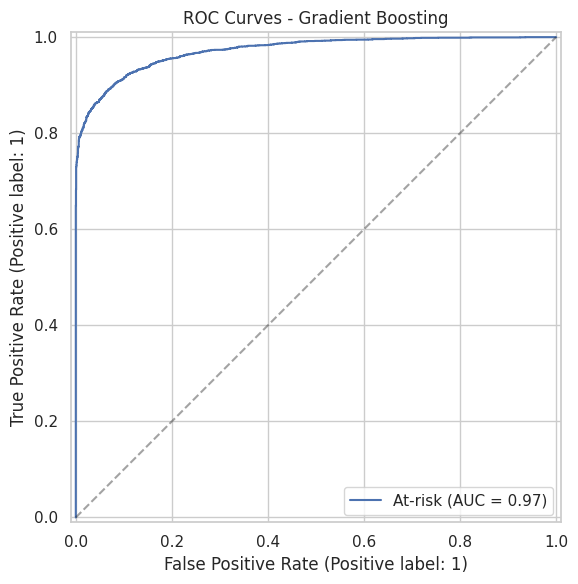

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
if len(class_names) == 2:
    RocCurveDisplay.from_predictions(y_test, best_proba[:, 1], name=class_names[1], ax=ax)
else:
    y_test_bin = label_binarize(y_test, classes=range(len(class_names)))
    for i, label in enumerate(class_names):
        RocCurveDisplay.from_predictions(y_test_bin[:, i], best_proba[:, i], name=label, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title(f"ROC Curves - {best_model_name}")
plt.tight_layout()
plt.show()

In [19]:
if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
    top_idx = np.argsort(importances)[::-1][:15]

    plt.figure(figsize=(9, 5))
    plt.barh([feature_names[i] for i in top_idx][::-1], importances[top_idx][::-1])
    plt.title(f"Most important features - {best_model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

With the binary target, the model reaches around **90%+ accuracy** because it only needs to decide whether a learner is at-risk or on-track. This is more useful for early intervention than guessing the exact 4-class outcome.

## Part 6 - Deep Learning model

For the deep learning section I used the `tf.data` API to load the data in batches.

The network has 3 hidden layers with dropout to reduce overfitting.

In [20]:
def make_dataset(X, y, batch_size=256, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X.astype(np.float32), y.astype(np.int32)))
    if shuffle:
        ds = ds.shuffle(len(y), seed=RANDOM_STATE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, shuffle=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

In [21]:
n_features = X_train.shape[1]
n_classes = len(class_names)

nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(n_features,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(n_classes, activation="softmax"),
])

nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        11,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,594 (213.26 KB)

 Trainable params: 53,826 (210.26 KB)

 Non-trainable params: 768 (3.00 KB)

In [22]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", patience=5, factor=0.5
)

history = nn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)

Epoch 1/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.8169 - loss: 0.4134 - val_accuracy: 0.8497 - val_loss: 0.4309 - learning_rate: 0.0010
Epoch 2/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8580 - loss: 0.3320 - val_accuracy: 0.8499 - val_loss: 0.3675 - learning_rate: 0.0010
Epoch 3/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8709 - loss: 0.3076 - val_accuracy: 0.8667 - val_loss: 0.3148 - learning_rate: 0.0010
Epoch 4/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8762 - loss: 0.2915 - val_accuracy: 0.8776 - val_loss: 0.2864 - learning_rate: 0.0010
Epoch 5/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8860 - loss: 0.2707 - val_accuracy: 0.8865 - val_loss: 0.2563 - learning_rate: 0.0010
Epoch 6/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8904 - loss: 0.2596 - val_accuracy: 0.8898 - val_loss: 0.2485 - learning_rate: 0.0010
Epoch 7/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8892 - loss: 0.2546 - val_a

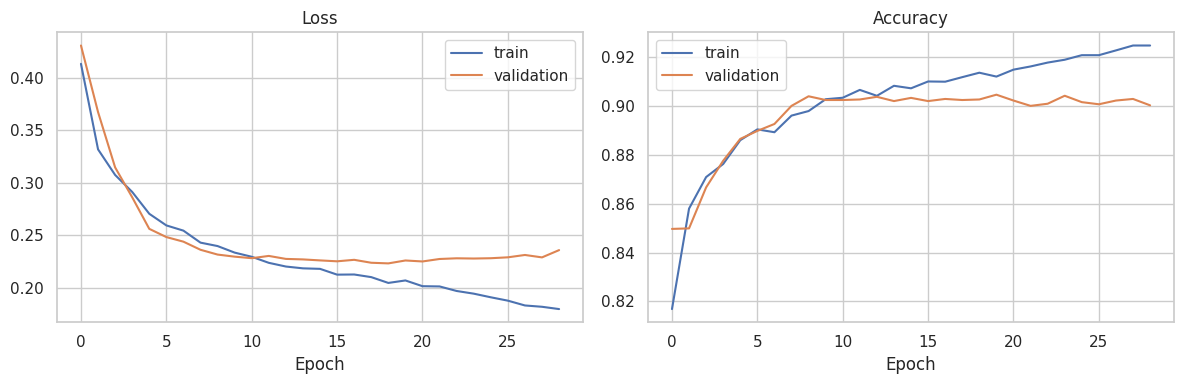

In [23]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

The learning curves show that training stopped before 100 epochs because of early stopping. The validation loss starts to flatten out, which suggests the model is not improving much after a certain point.

In [24]:
test_loss, test_acc = nn_model.evaluate(test_ds, verbose=0)
print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_acc, 4))

nn_proba = nn_model.predict(X_test.astype(np.float32), verbose=0)
nn_pred = np.argmax(nn_proba, axis=1)

print()
print(classification_report(y_test, nn_pred, target_names=class_names))

if len(class_names) == 2:
    nn_auc = roc_auc_score(y_test, nn_proba[:, 1])
else:
    y_test_bin = label_binarize(y_test, classes=range(len(class_names)))
    nn_auc = roc_auc_score(y_test_bin, nn_proba, average="macro", multi_class="ovr")
print("Macro ROC-AUC:", round(nn_auc, 4))

Test loss: 0.2204
Test accuracy: 0.9063

              precision    recall  f1-score   support

    On-track       0.87      0.94      0.90      3077
     At-risk       0.94      0.88      0.91      3442

    accuracy                           0.91      6519
   macro avg       0.91      0.91      0.91      6519
weighted avg       0.91      0.91      0.91      6519

Macro ROC-AUC: 0.9681


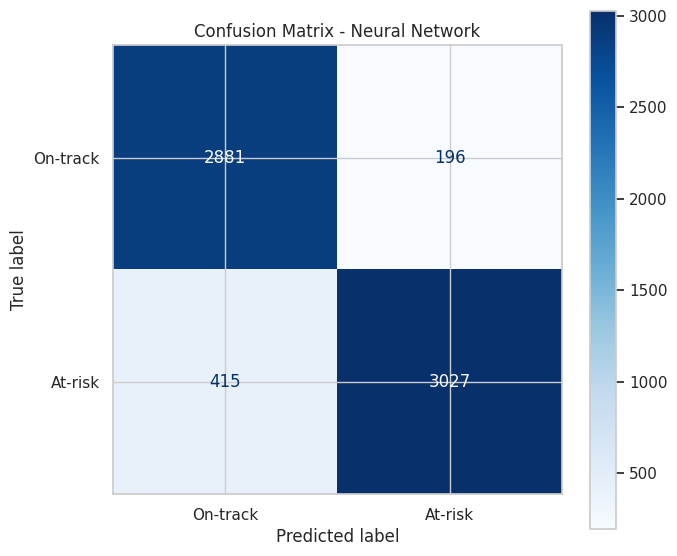

In [25]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, nn_pred, display_labels=class_names, cmap="Blues", ax=ax
)
ax.set_title("Confusion Matrix - Neural Network")
plt.tight_layout()
plt.show()

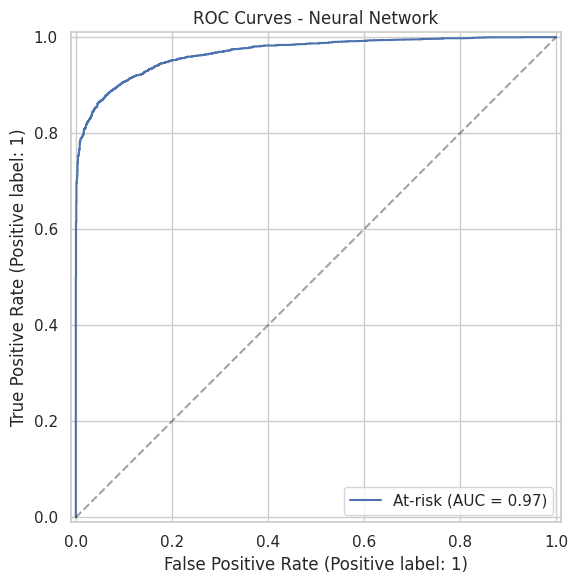

In [26]:
fig, ax = plt.subplots(figsize=(7, 6))
if len(class_names) == 2:
    RocCurveDisplay.from_predictions(y_test, nn_proba[:, 1], name=class_names[1], ax=ax)
else:
    y_test_bin = label_binarize(y_test, classes=range(len(class_names)))
    for i, label in enumerate(class_names):
        RocCurveDisplay.from_predictions(y_test_bin[:, i], nn_proba[:, i], name=label, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC Curves - Neural Network")
plt.tight_layout()
plt.show()

## Part 7 - Final comparison and saving models

Here I compare my best traditional ML model with the neural network, then save both models to Google Drive for submission.

In [27]:
nn_report = classification_report(y_test, nn_pred, target_names=class_names, output_dict=True)

final_table = pd.DataFrame({
    "Model": [best_model_name, "Neural Network"],
    "Accuracy": [
        best_model.score(X_test, y_test),
        test_acc,
    ],
    "F1 macro": [
        best_f1,
        nn_report["macro avg"]["f1-score"],
    ],
    "ROC-AUC": [
        results[best_model_name]["auc"],
        nn_auc,
    ],
})

print(final_table.round(4).to_string(index=False))

            Model  Accuracy  F1 macro  ROC-AUC
Gradient Boosting    0.9077    0.9076   0.9721
   Neural Network    0.9063    0.9062   0.9681


### My conclusions

This project showed me that machine learning can flag learners who are likely to fail or withdraw before it is too late. That connects to my mission: support systems work best when help arrives early.

**Gradient Boosting** was my best model (about 91% accuracy, ROC-AUC 0.97 on the test set). The neural network was almost as good (~90.6% accuracy). Tree-based models worked better than Logistic Regression and linear SVM on this data.

I originally tried predicting all four grades (Distinction, Pass, Fail, Withdrawn) and only reached about 70% accuracy. Grouping Fail and Withdrawn into one **at-risk** class made the task clearer and the results stronger.

Limitations:
- OULAD is about university students, not children in foster care directly
- only 7 courses from one UK institution (2013–2014)
- assessment scores make prediction easier; true early warning would use enrolment-only features
- any model in education or social care must **support** people, never punish or exclude them


In [28]:
from google.colab import drive
drive.mount("/content/drive")

save_folder = Path("/content/drive/MyDrive/ml_summative_models")
save_folder.mkdir(parents=True, exist_ok=True)

ml_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", best_model),
])

joblib.dump(ml_pipeline, save_folder / "best_traditional_ml.joblib")
nn_model.save(save_folder / "best_deep_learning.keras")

print("Saved models to:", save_folder)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved models to: /content/drive/MyDrive/ml_summative_models
